# 05 · Estacionalidad descriptiva (P6)

**Objetivo:** identificar qué productos muestran un patrón estacional estable de precios
**Preguntas que responde:** P6
**Entrada:** `data/processed/precios_limpio.parquet`
**Salida:** `images/p6_estacionalidad.png` (en la siguiente tanda)
**Decisiones tomadas:** D-07, D-18 (se cierra aquí)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/precios_limpio.parquet")

MIN_OBS = 5          # filas mínimas por mes y serie
MIN_MESES_ANIO = 6   # meses con dato para que una serie-año entre
MIN_MERCADOS = 3     # mercados mínimos por producto, año y mes

b = df[df["anio"] <= 2025].copy()
for c in ["producto", "mercado", "unidad"]:
    b[c] = b[c].astype(str)
b["mes"] = b["fecha"].dt.month

mu = (b.groupby(["producto", "mercado", "unidad", "anio", "mes"])
        .agg(precio=("precio_prom", "median"), n=("precio_prom", "size")).reset_index())
mu = mu[mu["n"] >= MIN_OBS]

# una sola etiqueta por (producto, mercado): la de más meses
meses = mu.groupby(["producto", "mercado", "unidad"]).size().rename("meses").reset_index()
dom = meses.sort_values("meses", ascending=False).drop_duplicates(["producto", "mercado"])
s = mu.merge(dom[["producto", "mercado", "unidad"]], on=["producto", "mercado", "unidad"])
s["lp"] = np.log(s["precio"])

g = s.groupby(["producto", "mercado", "anio"])["lp"]
s["k"] = g.transform("size")
s["dev"] = s["lp"] - g.transform("mean")
s = s[s["k"] >= MIN_MESES_ANIO]

prof = (s.groupby(["producto", "anio", "mes"])
          .agg(dev=("dev", "median"), mercados=("mercado", "nunique")).reset_index())
prof = prof[prof["mercados"] >= MIN_MERCADOS]

print("series-año:", s.groupby(["producto", "mercado", "anio"]).ngroups,
      "| productos:", s["producto"].nunique(),
      "| celdas producto-año-mes con 3+ mercados:", len(prof),
      "| productos:", prof["producto"].nunique())

series-año: 2227 | productos: 69 | celdas producto-año-mes con 3+ mercados: 2897 | productos: 53


In [3]:
def estabilidad(M, min_meses=5):
    cors = []
    for y in M.index:
        otros = M.drop(index=y).mean(axis=0, skipna=True)
        x = M.loc[y]
        ok = x.notna() & otros.notna()
        if ok.sum() >= min_meses and x[ok].std() > 0 and otros[ok].std() > 0:
            cors.append(np.corrcoef(x[ok], otros[ok])[0, 1])
    return (float(np.mean(cors)), len(cors)) if len(cors) >= 3 else (np.nan, len(cors))

filas, mats = [], {}
for p, d in prof.groupby("producto"):
    M = d.pivot(index="anio", columns="mes", values="dev")
    perfil = M.mean(axis=0, skipna=True).dropna()
    est, nanios = estabilidad(M)
    if len(perfil) < 6 or np.isnan(est):
        continue
    mats[p] = M
    filas.append(dict(producto=p, anios=nanios, meses=len(perfil), estabilidad=est,
                      amplitud_pct=(np.exp(perfil.max() - perfil.min()) - 1) * 100,
                      mes_pico=int(perfil.idxmax()), mes_valle=int(perfil.idxmin())))
res = pd.DataFrame(filas).sort_values("estabilidad", ascending=False).reset_index(drop=True)
print("productos evaluables:", len(res), "de", prof["producto"].nunique())

rng = np.random.default_rng(42)
nulos = []
for p, M in mats.items():
    for _ in range(100):
        Mp = M.copy()
        for y in Mp.index:
            v = Mp.loc[y].dropna().values
            Mp.loc[y, Mp.loc[y].notna()] = rng.permutation(v)
        e, _ = estabilidad(Mp)
        if not np.isnan(e):
            nulos.append(e)
q95 = float(np.percentile(nulos, 95))
print("estabilidad esperada por azar: mediana", round(float(np.median(nulos)), 2),
      "| percentil 95:", round(q95, 2))
for u in [0.5, 0.7, q95]:
    print(f"estabilidad >= {u:.2f}:", int((res["estabilidad"] >= u).sum()))
print(res.round(2).to_string(index=False))

productos evaluables: 44 de 53
estabilidad esperada por azar: mediana 0.01 | percentil 95: 0.31
estabilidad >= 0.50: 26
estabilidad >= 0.70: 14
estabilidad >= 0.31: 37
        producto  anios  meses  estabilidad  amplitud_pct  mes_pico  mes_valle
           Limón      6     12         0.98        378.13         3          8
 Arándano (blue)      4      9         0.95        275.69         9          2
        Frutilla      6     12         0.95        157.98         8         11
  Poroto granado      4      6         0.95         36.61        12          3
         Manzana      6     12         0.92         71.48         1          7
            Pera      6     12         0.91         56.12        12          5
       Alcachofa      6      8         0.91         95.00         6         10
            Haba      6      9         0.89        116.97         5         10
         Naranja      6     12         0.88        117.78         4          8
         Zapallo      6     12         0.8

In [4]:
import warnings

def estab_np(A, min_meses=5):
    cors = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for i in range(A.shape[0]):
            otros = np.nanmean(np.delete(A, i, axis=0), axis=0)
            x = A[i]
            ok = ~np.isnan(x) & ~np.isnan(otros)
            if ok.sum() >= min_meses and x[ok].std() > 0 and otros[ok].std() > 0:
                cors.append(np.corrcoef(x[ok], otros[ok])[0, 1])
    return (float(np.mean(cors)), len(cors)) if len(cors) >= 3 else (np.nan, len(cors))

def evaluar(prof, nrep=200, seed=42):
    rng = np.random.default_rng(seed)
    filas = []
    for p, d in prof.groupby("producto"):
        M = d.pivot(index="anio", columns="mes", values="dev").reindex(columns=range(1, 13))
        A = M.values.astype(float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            perfil = np.nanmean(A, axis=0)
        ok = ~np.isnan(perfil)
        est, nanios = estab_np(A)
        if ok.sum() < 6 or np.isnan(est):
            continue
        mayor, total = 0, 0
        for _ in range(nrep):
            B = A.copy()
            for i in range(B.shape[0]):
                idx = np.where(~np.isnan(B[i]))[0]
                B[i, idx] = rng.permutation(B[i, idx])
            e, _ = estab_np(B)
            if not np.isnan(e):
                total += 1
                mayor += e >= est
        pf = perfil[ok]
        filas.append(dict(producto=p, anios=nanios, meses=int(ok.sum()), estabilidad=est,
                          amplitud_pct=(np.exp(pf.max() - pf.min()) - 1) * 100,
                          mes_pico=int(np.argmax(np.where(ok, perfil, -np.inf)) + 1),
                          mes_valle=int(np.argmin(np.where(ok, perfil, np.inf)) + 1),
                          p_azar=(mayor + 1) / (total + 1)))
    return pd.DataFrame(filas).sort_values("estabilidad", ascending=False).reset_index(drop=True)

res1 = evaluar(prof)

comun = prof.groupby(["anio", "mes"])["dev"].median().rename("comun").reset_index()
prof_adj = prof.merge(comun, on=["anio", "mes"])
prof_adj["dev"] = prof_adj["dev"] - prof_adj["comun"]
res2 = evaluar(prof_adj)

cols = ["producto", "estabilidad", "amplitud_pct", "mes_pico", "mes_valle", "p_azar"]
cmp_ = res1[cols].merge(res2[cols], on="producto", suffixes=("", "_adj"))
cmp_["cambio"] = cmp_["estabilidad_adj"] - cmp_["estabilidad"]
pd.set_option("display.width", 220)
print(cmp_.round(2).to_string(index=False))

for nom, r_ in [("original", res1), ("sin movimiento común", res2)]:
    print(f"{nom}: evaluables {len(r_)}"
          f" | estab>=0.7 y p<=0.05: {int(((r_.estabilidad >= 0.7) & (r_.p_azar <= 0.05)).sum())}"
          f" | estab 0.5-0.7 y p<=0.05: {int(((r_.estabilidad >= 0.5) & (r_.estabilidad < 0.7) & (r_.p_azar <= 0.05)).sum())}"
          f" | p<=0.05: {int((r_.p_azar <= 0.05).sum())}")
print("meses pico (original):", res1["mes_pico"].value_counts().sort_index().to_dict())
print("meses valle (original):", res1["mes_valle"].value_counts().sort_index().to_dict())
print("no evaluables:", sorted(set(prof["producto"]) - set(res1["producto"])))

        producto  estabilidad  amplitud_pct  mes_pico  mes_valle  p_azar  estabilidad_adj  amplitud_pct_adj  mes_pico_adj  mes_valle_adj  p_azar_adj  cambio
           Limón         0.98        378.13         3          8    0.00             0.99            407.38             3              8        0.00    0.00
 Arándano (blue)         0.95        275.69         9          2    0.00             0.95            251.62             9              2        0.00   -0.00
        Frutilla         0.95        157.98         8         11    0.00             0.96            156.28             8             11        0.00    0.01
  Poroto granado         0.95         36.61        12          3    0.00             0.91             36.73            12              3        0.00   -0.03
         Manzana         0.92         71.48         1          7    0.00             0.90             80.27             1              7        0.00   -0.01
            Pera         0.91         56.12        12     

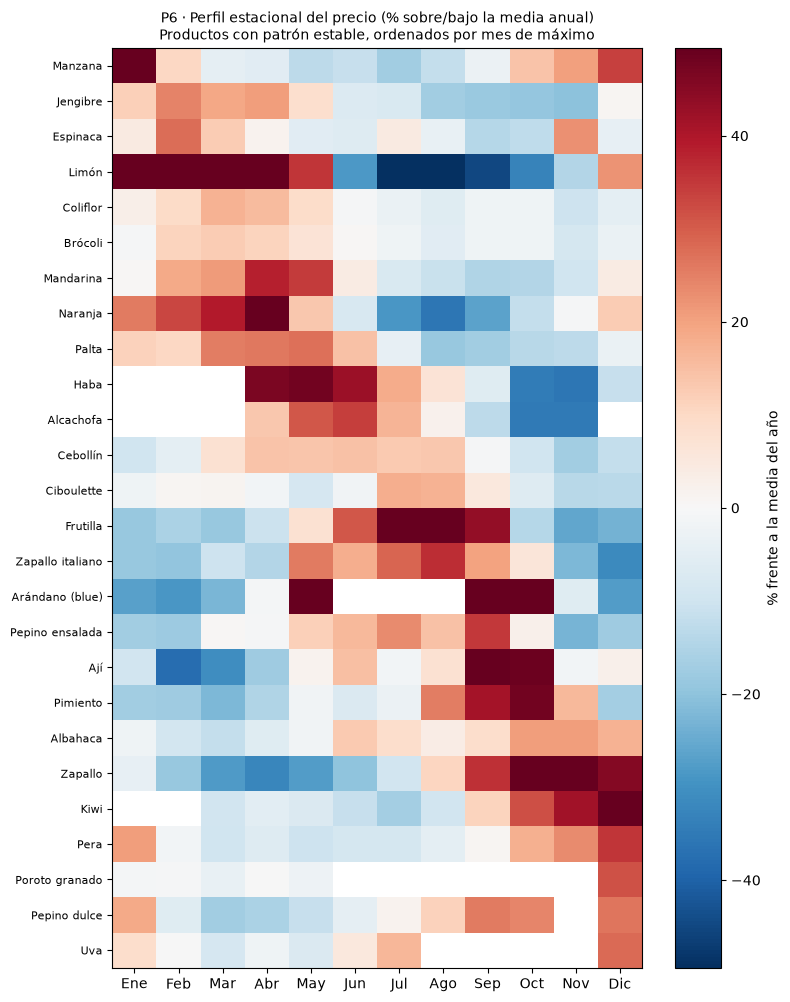

In [5]:
sel = res2[(res2["estabilidad"] >= 0.5) & (res2["p_azar"] <= 0.05)].sort_values("mes_pico")
filas = []
for p in sel["producto"]:
    M = prof_adj[prof_adj["producto"] == p].pivot(index="anio", columns="mes", values="dev")
    perfil = M.mean(axis=0, skipna=True).reindex(range(1, 13))
    filas.append((np.exp(perfil) - 1) * 100)
H = pd.DataFrame(filas, index=sel["producto"].values, columns=range(1, 13))

fig, ax = plt.subplots(figsize=(8, 0.32 * len(H) + 1.8))
lim = float(np.nanpercentile(np.abs(H.values), 95))
im = ax.imshow(np.ma.masked_invalid(H.values), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(12))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_yticks(range(len(H)))
ax.set_yticklabels(H.index, fontsize=8)
ax.set_title("P6 · Perfil estacional del precio (% sobre/bajo la media anual)\n"
             "Productos con patrón estable, ordenados por mes de máximo", fontsize=10)
fig.colorbar(im, ax=ax, label="% frente a la media del año")
fig.tight_layout()
fig.savefig("../images/p6_estacionalidad.png", dpi=150)